# Data Cleanser – Data Preprocessing & Feature Engineering


---

In [19]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

RAW   = "../Data/Raw/patient_health_records_raw.csv"
TRUTH = "../Data/External/ground_truth_clean_values.csv"   
PROC  = "../Data/Processed/"
VIZ   = "../Visualization/"

SEED  = 42
NUM   = ["age", "bmi", "cholesterol", "glucose"]           
CAT   = ["gender", "region"]                              
OUTCOLS = ["bmi", "blood_pressure", "cholesterol", "glucose"]  
print("Setup complete ✔")

Setup complete ✔


## Table of contents
1. **Part A** – Handling missing values (summary report, 6 imputation techniques, comparison)
2. **Part B** – Handling outliers (Z-score, IQR, Percentile, Winsorization, before-vs-after)
3. **Part C** – Final clean dataset, feature engineering, quality scorecard and brief conclusions

## Part A – Handling Missing Values
**Tasks covered:** (1) missing-value summary report, (2) six imputation techniques + comparison.

### A.1 Load the raw dataset

In [20]:
raw   = pd.read_csv(RAW)
truth = pd.read_csv(TRUTH)      

print("Raw dataset shape   :", raw.shape)
print("Ground-truth shape  :", truth.shape)
print()
raw.info()

Raw dataset shape   : (500, 9)
Ground-truth shape  : (500, 9)

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      500 non-null    str    
 1   age             470 non-null    float64
 2   gender          475 non-null    str    
 3   region          475 non-null    str    
 4   bmi             460 non-null    float64
 5   blood_pressure  500 non-null    float64
 6   cholesterol     465 non-null    float64
 7   glucose         465 non-null    float64
 8   disease_risk    500 non-null    int64  
dtypes: float64(5), int64(1), str(3)
memory usage: 42.8 KB


In [21]:
raw.head(10)

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,PT0001,57.0,Male,East,29.1,125.4,184.5,109.6,0
1,PT0002,36.0,Male,West,26.3,121.3,190.2,80.5,0
2,PT0003,63.0,NaN,South,28.3,124.9,205.9,92.1,1
3,PT0004,66.0,Male,East,30.3,127.3,217.2,107.4,1
4,PT0005,23.0,Male,North,21.9,110.8,159.6,90.3,0
5,PT0006,32.0,Female,West,29.4,120.2,184.4,98.0,0
6,PT0007,54.0,Female,South,20.8,111.3,206.0,110.7,0
7,PT0008,47.0,Female,East,67.1,115.1,229.7,86.4,0
8,PT0009,52.0,Male,South,27.3,115.8,200.7,108.1,0
9,PT0010,NaN,NaN,South,23.4,118.4,197.3,72.1,0


In [22]:
raw.describe(include='all').T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,500,500,PT0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,470.0,NaN,NaN,NaN,51.995745,14.364876,18.0,42.0,52.0,61.0,90.0
gender,475,2,Male,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,475,4,North,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,460.0,NaN,NaN,NaN,26.179565,6.498803,8.7,22.7,26.0,28.9,70.7
blood_pressure,500.0,NaN,NaN,NaN,126.078,20.075568,94.4,117.4,123.45,130.225,265.4
cholesterol,465.0,NaN,NaN,NaN,201.323871,56.163147,50.0,174.9,197.5,220.7,618.3
glucose,465.0,NaN,NaN,NaN,99.551828,52.915534,65.0,83.5,92.1,100.1,499.0
disease_risk,500.0,NaN,NaN,NaN,0.394,0.489124,0.0,0.0,0.0,1.0,1.0


### A.2 Missing-value summary report (percentage per column) – *Task 1*

In [23]:
miss = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
}).sort_values("missing_%", ascending=False)
miss.to_csv(PROC + "missing_value_summary.csv")

total = raw.isna().sum().sum()
print(f"Total missing cells               : {total} ({total / raw.size * 100:.2f}% of all cells)")
print(f"Rows with >= 1 missing value      : {raw.isna().any(axis=1).sum()} ({raw.isna().any(axis=1).mean() * 100:.1f}% of rows)")
print(f"Rows that would be lost by dropna : {raw.isna().any(axis=1).sum()}  -> imputation is clearly preferable")
miss

Total missing cells               : 190 (4.22% of all cells)
Rows with >= 1 missing value      : 164 (32.8% of rows)
Rows that would be lost by dropna : 164  -> imputation is clearly preferable


,dtype,missing_count,missing_%
bmi,float64,40,8.0
glucose,float64,35,7.0
cholesterol,float64,35,7.0
age,float64,30,6.0
region,str,25,5.0
gender,str,25,5.0
patient_id,str,0,0.0
blood_pressure,float64,0,0.0
disease_risk,int64,0,0.0


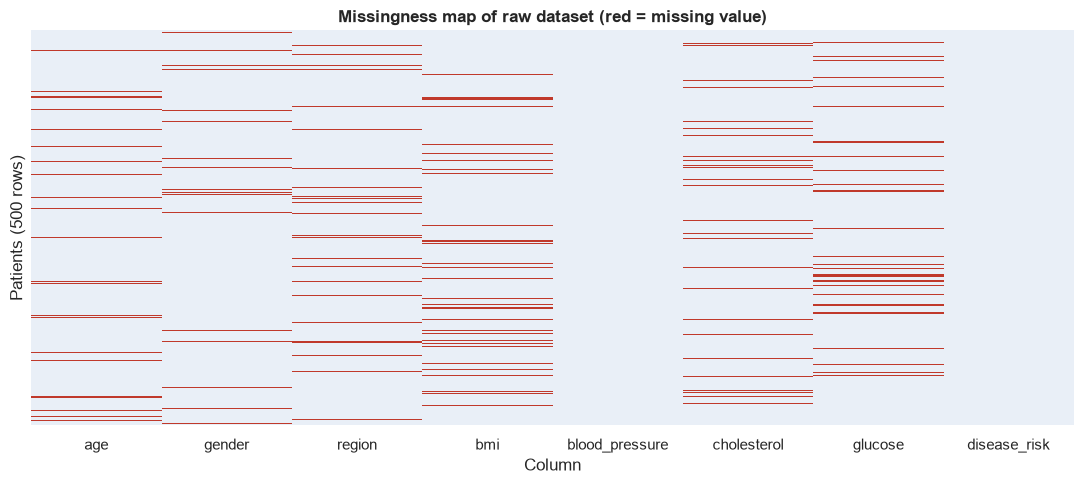

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(raw.drop(columns="patient_id").isna(), cbar=False, yticklabels=False,
            cmap=ListedColormap(["#e9eff7", "#c0392b"]), ax=ax)
ax.set_title("Missingness map of raw dataset (red = missing value)")
ax.set_xlabel("Column"); ax.set_ylabel("Patients (500 rows)")
plt.tight_layout(); plt.savefig(VIZ + "01_missing_values_map.png", dpi=150)
plt.show()

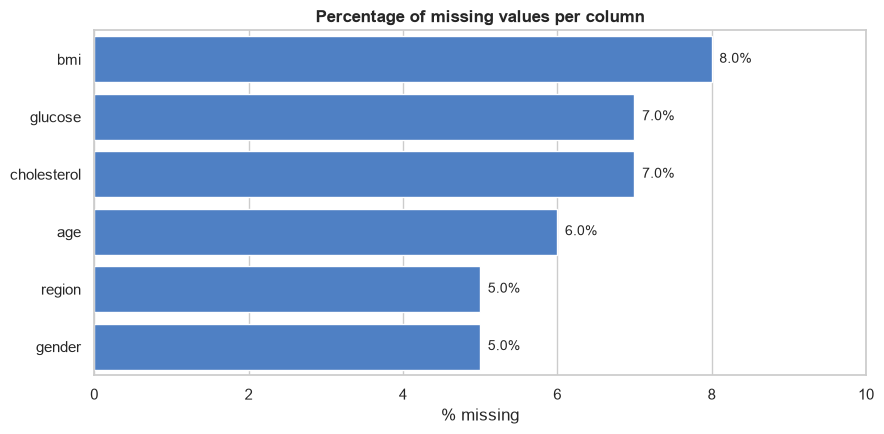

In [25]:
m = miss[miss["missing_%"] > 0].reset_index().rename(columns={"index": "column"})
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=m, x="missing_%", y="column", color="#3b7dd8", ax=ax)
for i, v in enumerate(m["missing_%"]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_title("Percentage of missing values per column"); ax.set_xlabel("% missing"); ax.set_ylabel("")
ax.set_xlim(0, m["missing_%"].max() + 2)
plt.tight_layout(); plt.savefig(VIZ + "02_missing_percentage_bar.png", dpi=150)
plt.show()

**Interpretation – missing values**
* **190 cells (4.22 %)** are missing, spread over **164 of the 500 patients (32.8 %)**. Simply dropping incomplete rows (`dropna`) would throw away a third of the data, so imputation is the right choice.
* `bmi` has the highest rate (**8 %**), followed by `cholesterol` and `glucose` (**7 % each**), `age` (**6 %**), and `gender` / `region` (**5 % each**). `patient_id`, `blood_pressure` and `disease_risk` are complete.
* The red dots in the map are scattered randomly with no block pattern, which suggests the data are *missing completely at random* – the situation in which the imputation techniques below are valid. No column exceeds 10 %, so none needs to be dropped.

### A.3 How will we score the imputations?
Because this dataset was *synthetically* generated, we kept a copy of the **true values before they were hidden** (`Data/External/ground_truth_clean_values.csv`).  
For every cell that was missing we can therefore measure the real imputation error:

* **Numeric columns** → RMSE and *normalised* RMSE (`RMSE / std of true column`, so columns with different units are comparable). Lower is better.
* **Categorical columns** → accuracy of the imputed category. Higher is better.

In [26]:
missing_mask = raw[NUM + CAT].isna()

def evaluate(imputed, name):
    """Score an imputed dataframe against the ground truth, on the originally-missing cells only."""
    row = {"method": name}
    for c in NUM:
        m = missing_mask[c]
        err = imputed.loc[m, c].astype(float) - truth.loc[m, c].astype(float)
        row[f"{c}_RMSE"] = np.sqrt((err ** 2).mean())
        row[f"{c}_NRMSE"] = row[f"{c}_RMSE"] / truth[c].std()
    for c in CAT:
        m = missing_mask[c]
        row[f"{c}_acc"] = (imputed.loc[m, c] == truth.loc[m, c]).mean()
    row["avg_NRMSE"] = np.mean([row[f"{c}_NRMSE"] for c in NUM])
    row["avg_cat_accuracy"] = np.mean([row[f"{c}_acc"] for c in CAT])
    row["bmi_imputed_std"] = imputed.loc[missing_mask["bmi"], "bmi"].astype(float).std()   # spread of imputed values
    return row

imputed = {}     # name -> fully imputed dataframe
print("Missing cells to be imputed:", int(missing_mask.sum().sum()))

Missing cells to be imputed: 190


### A.4 Technique 1 – Simple Imputer (numerical): mean / median

In [27]:
from sklearn.impute import SimpleImputer

# --- mean imputation ---
mean_df = raw.copy()
mean_df[NUM] = SimpleImputer(strategy="mean").fit_transform(raw[NUM])
# --- median imputation ---
median_df = raw.copy()
median_df[NUM] = SimpleImputer(strategy="median").fit_transform(raw[NUM])
for d in (mean_df, median_df):
    d["age"] = d["age"].round()                      # age is an integer

print("BMI – statistics before / after imputation")
cmp_bmi = pd.DataFrame({
    "raw (observed only)": raw["bmi"].describe(),
    "after MEAN impute": mean_df["bmi"].describe(),
    "after MEDIAN impute": median_df["bmi"].describe(),
}).round(2)
print("mean used  :", round(raw['bmi'].mean(), 2), "| median used :", round(raw['bmi'].median(), 2))
cmp_bmi

BMI – statistics before / after imputation
mean used  : 26.18 | median used : 26.0


,raw (observed only),after MEAN impute,after MEDIAN impute
count,460.00,500.00,500.00
mean,26.18,26.18,26.17
std,6.50,6.23,6.23
min,8.70,8.70,8.70
25%,22.70,23.00,23.00
50%,26.00,26.18,26.00
75%,28.90,28.52,28.52
max,70.70,70.70,70.70


**Interpretation – mean / median**
* The observed BMI mean (26.18) and median (26.00) are close, so both give almost the same result for BMI. The standard deviation shrinks from 6.50 to 6.23 and a spike appears at the centre of the distribution – the typical side-effect of constant imputation (variance is under-estimated and correlations are weakened).
* Because the data contain extreme values (BMI 8.7 – 70.7), the *mean* is pulled by outliers while the *median* is robust. The effect is largest for glucose (spikes up to 499 mg/dL): see the comparison in A.8, where median imputation has a clearly lower glucose error than mean imputation.

### A.5 Technique 2 – Simple Imputer (categorical): most-frequent value for `region`

In [28]:
cat_df = raw.copy()
cat_df[["region"]] = SimpleImputer(strategy="most_frequent").fit_transform(raw[["region"]])
print("Most frequent region used for imputation:", raw["region"].mode()[0])
pd.DataFrame({"before": raw["region"].value_counts(dropna=False),
              "after": cat_df["region"].value_counts(dropna=False)}).fillna(0).astype(int)

Most frequent region used for imputation: North


,before,after
region,,
East,97,97
North,155,180
South,144,144
West,79,79
NaN,25,0


### A.5b Technique 3 – Most Frequent Imputation for `gender`

In [29]:
gender_mode = raw["gender"].mode()[0]
gender_df = raw.copy()
gender_df["gender"] = gender_df["gender"].fillna(gender_mode)
print("Most common gender:", gender_mode)
pd.DataFrame({"before": raw["gender"].value_counts(dropna=False),
              "after": gender_df["gender"].value_counts(dropna=False)}).fillna(0).astype(int)

Most common gender: Male


,before,after
gender,,
Female,225,225
Male,250,275
NaN,25,0


**Interpretation – most-frequent imputation**
* `region`: North (the mode) grows from 155 to 180 rows; `gender`: Male grows from 250 to 275 rows. Mode imputation is simple and keeps the column valid, but it **inflates the majority class** and can bias the category proportions.
* With only 5 % missing the distortion is small. In this dataset gender and region carry almost no information about the other columns, so there is no better signal to exploit than the majority value.

### A.6 Technique 4 – Missing Indicator + Random Sample Imputation
Step 1: add a binary column `<col>_was_missing` (so the model can still learn from *the fact* that a value was missing).  
Step 2: fill each hole with a value drawn **at random from the observed values of the same column** – this keeps the original distribution (mean *and* spread).

In [30]:
rs_df = raw.copy()
rng = np.random.default_rng(SEED)
for c in NUM + CAT:
    mask = raw[c].isna()
    rs_df[f"{c}_was_missing"] = mask.astype(int)                       # missing indicator
    observed = raw[c].dropna().values
    rs_df.loc[mask, c] = rng.choice(observed, mask.sum(), replace=True)  # random sample imputation
rs_df["age"] = rs_df["age"].astype(float).round()

print("New indicator columns:", [c for c in rs_df.columns if c.endswith("_was_missing")])
rs_df[[c for c in rs_df.columns if c.endswith("_was_missing")]].sum().to_frame("rows flagged as missing")

New indicator columns: ['age_was_missing', 'bmi_was_missing', 'cholesterol_was_missing', 'glucose_was_missing', 'gender_was_missing', 'region_was_missing']


,rows flagged as missing
age_was_missing,30
bmi_was_missing,40
cholesterol_was_missing,35
glucose_was_missing,35
gender_was_missing,25
region_was_missing,25


### A.7 Technique 5 & 6 – KNN Imputer and MICE (multivariate)
Both techniques use the **other columns** to estimate a missing value:

* **KNN Imputer** – finds the *k = 5* most similar patients (distance computed on the standardised features) and averages their values (distance-weighted).
* **MICE** (`IterativeImputer`) – chained equations: each column with holes is regressed on all the others (Bayesian Ridge), and the loop is repeated until the estimates stabilise (15 rounds).

Categorical columns are encoded first (gender → 0/1, region → one-hot) so they can take part in the distance / regression, then decoded back to labels.

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer          # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge

REGIONS = ["East", "North", "South", "West"]
FEATS = ["age", "bmi", "blood_pressure", "cholesterol", "glucose"]

def encode(df):
    X = df[FEATS].astype(float).copy()
    X["gender_male"] = df["gender"].map({"Male": 1.0, "Female": 0.0})
    for r in REGIONS:
        X["region_" + r] = np.where(df["region"].isna(), np.nan, (df["region"] == r).astype(float))
    return X

def multivariate_impute(df, kind="knn"):
    X = encode(df)
    sc = StandardScaler()
    Xs = sc.fit_transform(X)                                         # NaNs are ignored when fitting
    if kind == "knn":
        imp = KNNImputer(n_neighbors=5, weights="distance")
    else:
        imp = IterativeImputer(estimator=BayesianRidge(), max_iter=15, random_state=SEED)
    Xi = pd.DataFrame(sc.inverse_transform(imp.fit_transform(Xs)), columns=X.columns, index=df.index)

    out = df.copy()
    for c in ["bmi", "blood_pressure", "cholesterol", "glucose", "age"]:
        out[c] = out[c].fillna(Xi[c])
    out["age"] = out["age"].round().clip(18, 90)
    out["gender"] = out["gender"].fillna(pd.Series(np.where(Xi["gender_male"] >= 0.5, "Male", "Female"), index=df.index))
    reg_cols = ["region_" + r for r in REGIONS]
    out["region"] = out["region"].fillna(pd.Series(np.array(REGIONS)[Xi[reg_cols].values.argmax(axis=1)], index=df.index))
    return out

knn_df  = multivariate_impute(raw, "knn")
mice_df = multivariate_impute(raw, "mice")
print("KNN  – missing left:", int(knn_df[NUM + CAT].isna().sum().sum()))
print("MICE – missing left:", int(mice_df[NUM + CAT].isna().sum().sum()))

KNN  – missing left: 0
MICE – missing left: 0


### A.8 Compare all imputation techniques – *Task 2 (comparison)*

In [32]:
# Combine the simple techniques into complete datasets (numeric strategy + categorical strategy)
mean_full = mean_df.copy();   mean_full[CAT] = SimpleImputer(strategy="most_frequent").fit_transform(raw[CAT])
median_full = median_df.copy(); median_full[CAT] = SimpleImputer(strategy="most_frequent").fit_transform(raw[CAT])

imputed = {
    "Mean + Most-frequent": mean_full,
    "Median + Most-frequent": median_full,
    "Missing-indicator + Random sample": rs_df[raw.columns.tolist()],
    "KNN (k=5)": knn_df,
    "MICE (Bayesian Ridge)": mice_df,
}
results = pd.DataFrame([evaluate(d, n) for n, d in imputed.items()]).set_index("method")
cols = ["age_NRMSE", "bmi_NRMSE", "cholesterol_NRMSE", "glucose_NRMSE", "avg_NRMSE",
        "gender_acc", "region_acc", "avg_cat_accuracy"]
results[cols].round(3)

,age_NRMSE,bmi_NRMSE,cholesterol_NRMSE,glucose_NRMSE,avg_NRMSE,gender_acc,region_acc,avg_cat_accuracy
method,,,,,,,,
Mean + Most-frequent,0.934,0.907,1.292,1.376,1.127,0.60,0.32,0.46
Median + Most-frequent,0.934,0.902,1.253,1.014,1.026,0.60,0.32,0.46
Missing-indicator + Random sample,1.533,1.619,2.344,1.533,1.757,0.40,0.20,0.30
KNN (k=5),0.808,1.014,1.591,2.799,1.553,0.56,0.08,0.32
MICE (Bayesian Ridge),0.994,0.853,1.124,1.305,1.069,0.64,0.32,0.48


In [33]:
rmse_tbl = results[[f"{c}_RMSE" for c in NUM]].round(2)
rmse_tbl["true std of BMI (missing cells)"] = round(truth.loc[missing_mask["bmi"], "bmi"].std(), 2)
rmse_tbl["std of imputed BMI values"] = results["bmi_imputed_std"].round(2)
rmse_tbl

,age_RMSE,bmi_RMSE,cholesterol_RMSE,glucose_RMSE,true std of BMI (missing cells),std of imputed BMI values
method,,,,,,
Mean + Most-frequent,13.36,3.78,41.90,16.32,3.79,0.00
Median + Most-frequent,13.36,3.76,40.62,12.03,3.79,0.00
Missing-indicator + Random sample,21.93,6.75,76.03,18.18,3.79,6.81
KNN (k=5),11.56,4.23,51.62,33.19,3.79,3.80
MICE (Bayesian Ridge),14.22,3.56,36.44,15.47,3.79,1.13


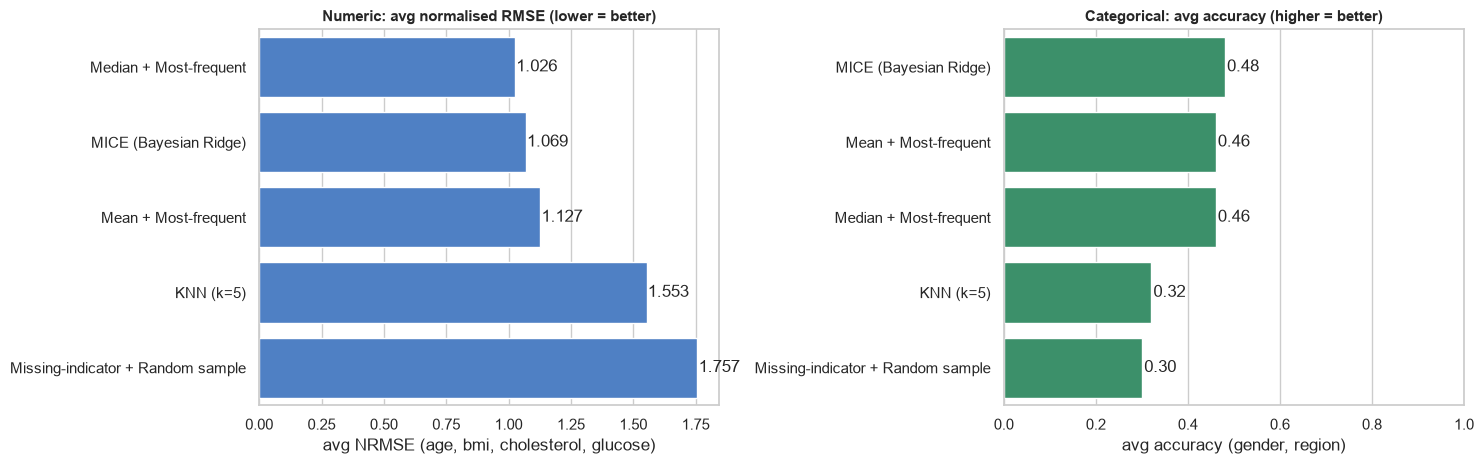

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
order = results.sort_values("avg_NRMSE").index
sns.barplot(x=results.loc[order, "avg_NRMSE"], y=order, color="#3b7dd8", ax=axes[0])
for i, v in enumerate(results.loc[order, "avg_NRMSE"]):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center")
axes[0].set_title("Numeric: avg normalised RMSE (lower = better)", fontsize=11)
axes[0].set_xlabel("avg NRMSE (age, bmi, cholesterol, glucose)"); axes[0].set_ylabel("")

order2 = results.sort_values("avg_cat_accuracy", ascending=False).index
sns.barplot(x=results.loc[order2, "avg_cat_accuracy"], y=order2, color="#2e9e6b", ax=axes[1])
for i, v in enumerate(results.loc[order2, "avg_cat_accuracy"]):
    axes[1].text(v + 0.005, i, f"{v:.2f}", va="center")
axes[1].set_title("Categorical: avg accuracy (higher = better)", fontsize=11)
axes[1].set_xlabel("avg accuracy (gender, region)"); axes[1].set_ylabel(""); axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.savefig(VIZ + "03_imputation_error_comparison.png", dpi=150)
plt.show()

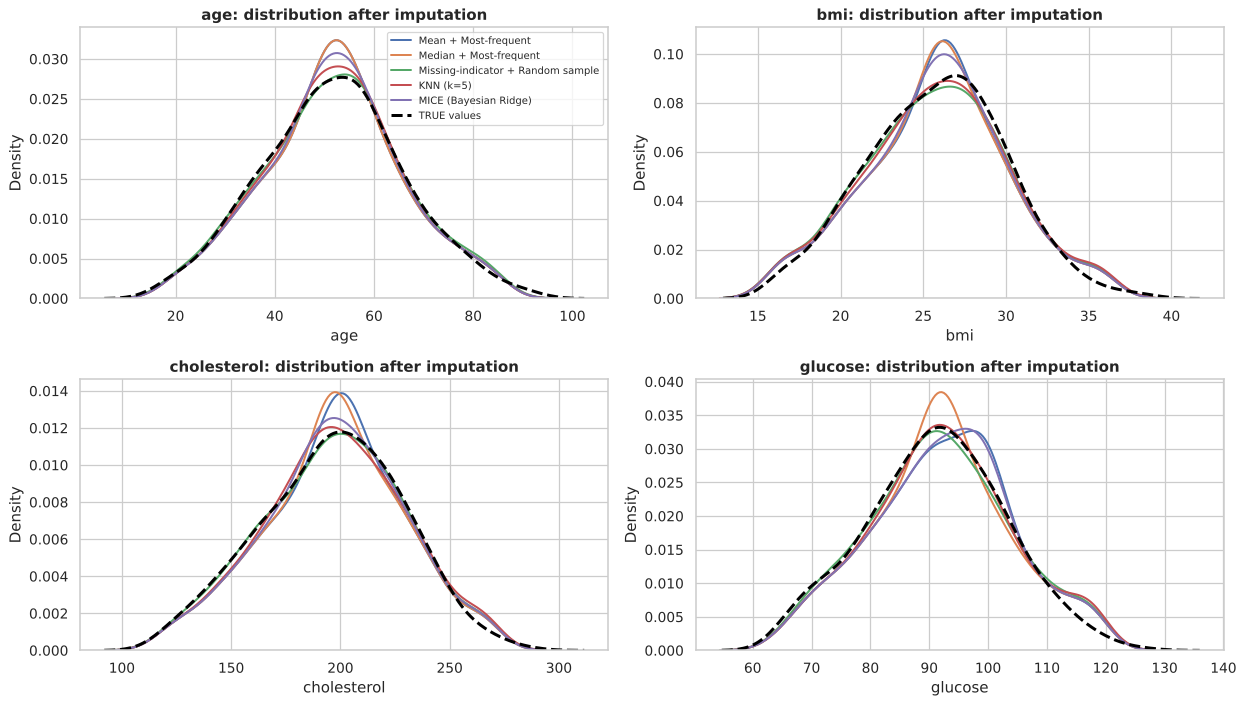

In [17]:
# How does each method change the DISTRIBUTION of the column? (trimmed to the 1st-99th percentile for readability)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(axes.ravel(), NUM):
    lo, hi = truth[c].quantile([0.01, 0.99])
    for name, d in imputed.items():
        sns.kdeplot(d[c].astype(float).clip(lo, hi), ax=ax, label=name, lw=1.6)
    sns.kdeplot(truth[c].astype(float), ax=ax, label="TRUE values", color="black", lw=2.4, ls="--")
    ax.set_title(f"{c}: distribution after imputation"); ax.set_xlabel(c)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(VIZ + "04_imputation_distribution_comparison.png", dpi=150)
plt.show()

**Interpretation – comparison of the six techniques (scored against the hidden true values)**

| Technique | Strength | Weakness |
|---|---|---|
| Mean / Median + Most-frequent | fast, stable; median is robust to outliers | ignores relationships, shrinks variance |
| Missing-indicator + Random sample | keeps the original distribution and *flags* missingness for the model | adds noise; also copies outliers into the missing cells (imputed BMI std 6.8) |
| KNN (k = 5) | uses similar patients | distance is dominated by outlier-inflated features → large glucose error |
| MICE (Bayesian Ridge) | models each column from all others, preserves relationships | regression is also disturbed by extreme values |

* On the **raw** data (outliers still present) the **median** has the lowest average normalised RMSE (**1.026**), followed by MICE (1.069) and mean (1.127); KNN (1.553) and random sampling (1.757) are worst.
* Every score is close to or above 1.0, i.e. no technique beats "guess the average" by much. The reason is the extreme values in the *other* columns – they distort KNN distances, MICE regressions and the random sampling pool. **This ranking changes once outliers are neutralised** – see section C.1, where MICE becomes the clear winner.
* For the categorical columns no technique is reliably better than predicting the majority class (accuracy ≈ 0.3 for region, ≈ 0.6 for gender, computed on only 25 cells each, so differences of a few percent are noise).

### A.9 Select the best imputation and save all versions

In [18]:
best_num = results["avg_NRMSE"].idxmin()
best_cat = results["avg_cat_accuracy"].idxmax()
print("Best numeric imputation     :", best_num, f"(avg NRMSE = {results.loc[best_num, 'avg_NRMSE']:.3f})")
print("Best categorical imputation :", best_cat, f"(avg accuracy = {results.loc[best_cat, 'avg_cat_accuracy']:.3f})")

best = imputed[best_num].copy()
best[CAT] = imputed[best_cat][CAT]

# save every version + the comparison table
files = {"Mean + Most-frequent": "imputed_mean_mode.csv", "Median + Most-frequent": "imputed_median_mode.csv",
         "Missing-indicator + Random sample": "imputed_random_sample_with_indicators.csv",
         "KNN (k=5)": "imputed_knn.csv", "MICE (Bayesian Ridge)": "imputed_mice.csv"}
for name, fn in files.items():
    d = rs_df if name.startswith("Missing") else imputed[name]
    d.to_csv(PROC + fn, index=False)
best.to_csv(PROC + "imputed_best.csv", index=False)
results.round(4).to_csv(PROC + "imputation_comparison.csv")
print("Remaining missing values in best dataset:", int(best.isna().sum().sum()))
print("Saved ->", PROC)

Best numeric imputation     : Median + Most-frequent (avg NRMSE = 1.026)
Best categorical imputation : MICE (Bayesian Ridge) (avg accuracy = 0.480)
Remaining missing values in best dataset: 0
Saved -> ../Data/Processed/

## Part B – Handling Outliers
**Tasks covered:** (3) detect & remove outliers with Z-score, IQR and Percentile methods, (4) Winsorization, (5) before-vs-after comparison.

### B.1 Load the imputed dataset from Part A
We continue from `imputed_best.csv` (all missing values already filled by the best technique of Part A).

In [19]:
from scipy import stats
from scipy.stats import mstats
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

df    = pd.read_csv(PROC + "imputed_best.csv")
raw   = pd.read_csv(RAW)
truth = pd.read_csv(TRUTH)
print("Dataset shape:", df.shape, "| missing cells:", int(df.isna().sum().sum()))
df[OUTCOLS].describe().T.round(2).assign(skew=df[OUTCOLS].skew().round(2))

Dataset shape: (500, 9) | missing cells: 0

,count,mean,std,min,25%,50%,75%,max,skew
bmi,500.0,26.17,6.23,8.7,23.00,26.00,28.52,70.7,2.93
blood_pressure,500.0,126.08,20.08,94.4,117.40,123.45,130.22,265.4,4.20
cholesterol,500.0,201.06,54.17,50.0,177.08,197.50,219.18,618.3,3.85
glucose,500.0,99.03,51.06,65.0,84.28,92.10,99.30,499.0,6.09


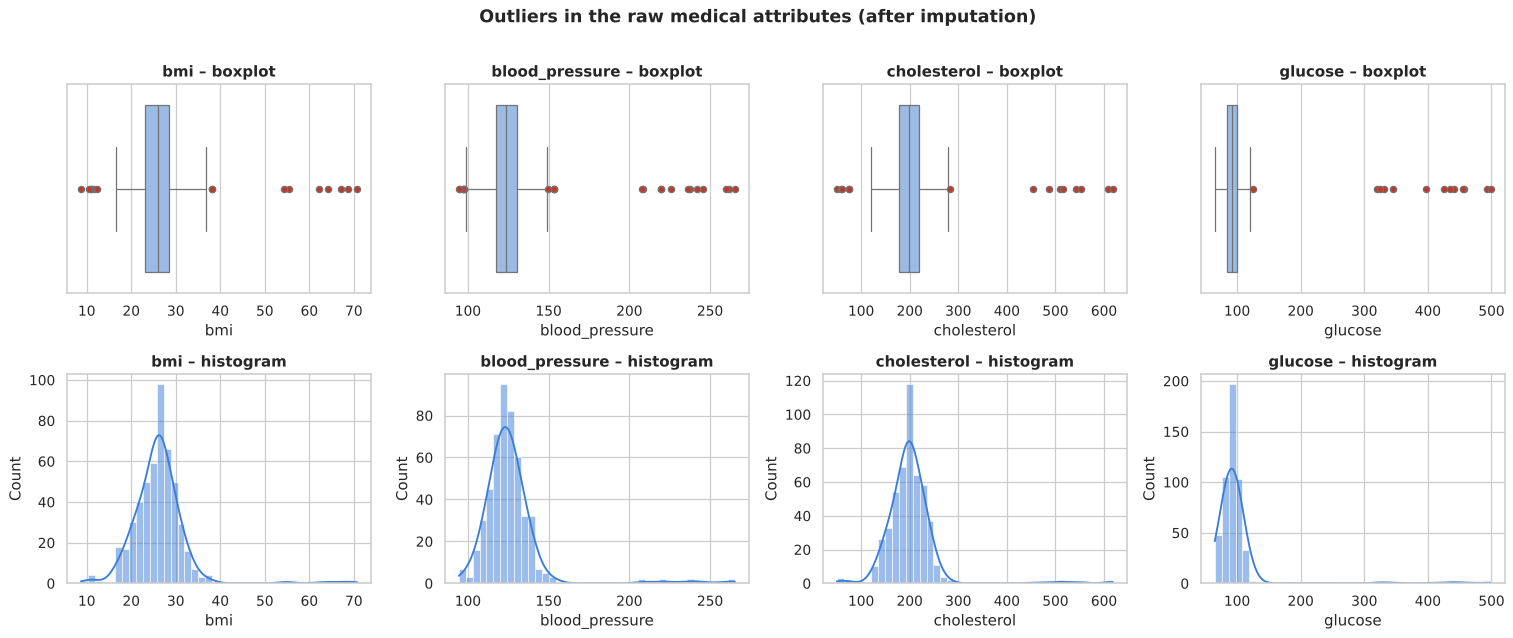

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for j, c in enumerate(OUTCOLS):
    sns.boxplot(x=df[c], ax=axes[0, j], color="#8fb8f0", flierprops=dict(marker="o", markerfacecolor="#c0392b", markersize=5))
    axes[0, j].set_title(f"{c} – boxplot")
    sns.histplot(df[c], kde=True, ax=axes[1, j], color="#3b7dd8", bins=40)
    axes[1, j].set_title(f"{c} – histogram")
plt.suptitle("Outliers in the raw medical attributes (after imputation)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.savefig(VIZ + "05_outliers_before_treatment.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation – outliers before treatment**
The boxplots show long right tails and (for BMI and cholesterol) a few extreme low values. Roughly 12–13 values per column are physiologically implausible: BMI 8.7 – 70.7, systolic blood pressure up to 265 mmHg, cholesterol 50 – 618 mg/dL and glucose up to 499 mg/dL. The average absolute skewness of the four columns is about **4.3** (a normal distribution has 0), which would hurt any model that assumes roughly symmetric inputs.

### B.2 Reusable detection helpers

In [21]:
def z_flags(s, thr=3.0):
    """Classic Z-score rule: |(x - mean) / std| > thr"""
    return ((s - s.mean()) / s.std()).abs() > thr

def iqr_bounds(s, k=1.5):
    """Tukey fences: [Q1 - k*IQR , Q3 + k*IQR]"""
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return q1 - k * i, q3 + k * i

def iqr_flags(s, k=1.5):
    lo, hi = iqr_bounds(s, k)
    return (s < lo) | (s > hi)

def modz_flags(s, thr=3.5):
    """Robust 'modified Z-score' (median / MAD based) - bonus method"""
    mad = (s - s.median()).abs().median()
    return (0.6745 * (s - s.median()) / mad).abs() > thr
print("helpers ready")

helpers ready

### B.3 Z-score method – extreme `cholesterol` and `glucose` values (*Task 3a*)

In [22]:
z_rows = []
for c in ["cholesterol", "glucose"]:
    f = z_flags(df[c])
    z = (df[c] - df[c].mean()) / df[c].std()
    z_rows.append({"column": c, "mean": df[c].mean(), "std": df[c].std(), "outliers (|z|>3)": int(f.sum()),
                   "too high": int((z > 3).sum()), "too low": int((z < -3).sum()),
                   "min flagged": df.loc[f, c].min() if f.any() else np.nan, "max flagged": df.loc[f, c].max() if f.any() else np.nan})
pd.DataFrame(z_rows).round(2).set_index("column")

,mean,std,outliers (|z|>3),too high,too low,min flagged,max flagged
column,,,,,,,
cholesterol,201.06,54.17,8,8,0,453.9,618.3
glucose,99.03,51.06,12,12,0,320.6,499.0


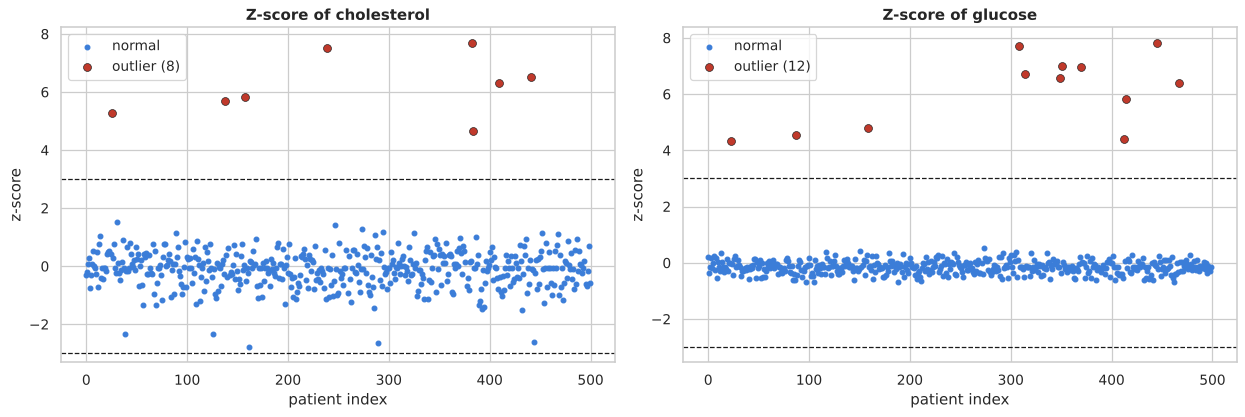

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, c in zip(axes, ["cholesterol", "glucose"]):
    z = (df[c] - df[c].mean()) / df[c].std()
    flag = z.abs() > 3
    ax.scatter(df.index[~flag], z[~flag], s=14, color="#3b7dd8", label="normal")
    ax.scatter(df.index[flag], z[flag], s=40, color="#c0392b", label=f"outlier ({flag.sum()})", edgecolor="k", lw=0.5)
    ax.axhline(3, color="k", ls="--", lw=1); ax.axhline(-3, color="k", ls="--", lw=1)
    ax.set_title(f"Z-score of {c}"); ax.set_xlabel("patient index"); ax.set_ylabel("z-score"); ax.legend()
plt.tight_layout(); plt.savefig(VIZ + "06_zscore_cholesterol_glucose.png", dpi=150)
plt.show()

In [24]:
# remove patients whose cholesterol OR glucose is an extreme Z-score outlier
z_mask = z_flags(df["cholesterol"]) | z_flags(df["glucose"])
df_z = df.loc[~z_mask].copy()
print(f"Rows before: {len(df)} | removed: {int(z_mask.sum())} | rows after: {len(df_z)}")
df_z.to_csv(PROC + "outliers_removed_zscore.csv", index=False)

Rows before: 500 | removed: 20 | rows after: 480

**Interpretation – Z-score**
* Z-score flagged **8 cholesterol** values (all too high) and **12 glucose** values (all too high); removing these patients drops **20 rows (4 %)**.
* **Weakness (masking effect):** the outliers themselves inflate the standard deviation (cholesterol std 54 vs about 32 for the uncorrupted data), so the threshold of ±3 sits far away. The extremely *low* cholesterol values (45–85 mg/dL) were never flagged because they would need z < −3. The rule also assumes a roughly normal distribution.

### B.4 IQR method – unusual `bmi` values (*Task 3b*)

In [25]:
lo, hi = iqr_bounds(df["bmi"])
q1, q3 = df["bmi"].quantile([0.25, 0.75])
iqr_mask = iqr_flags(df["bmi"])
print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | IQR = {q3 - q1:.2f}")
print(f"Lower fence = {lo:.2f} | Upper fence = {hi:.2f}")
print(f"BMI outliers: {int(iqr_mask.sum())}  (too low: {int((df['bmi'] < lo).sum())}, too high: {int((df['bmi'] > hi).sum())})")
df.loc[iqr_mask, ["patient_id", "age", "bmi", "disease_risk"]].sort_values("bmi").head(20)

Q1 = 23.00 | Q3 = 28.52 | IQR = 5.52
Lower fence = 14.71 | Upper fence = 36.81
BMI outliers: 15  (too low: 6, too high: 9)

,patient_id,age,bmi,disease_risk
11,PT0012,64.0,8.7,0
483,PT0484,61.0,10.5,0
317,PT0318,52.0,10.9,0
338,PT0339,69.0,11.0,1
281,PT0282,26.0,11.6,0
428,PT0429,31.0,12.2,0
288,PT0289,48.0,38.1,1
135,PT0136,37.0,38.1,1
409,PT0410,33.0,54.3,1
115,PT0116,44.0,55.4,0


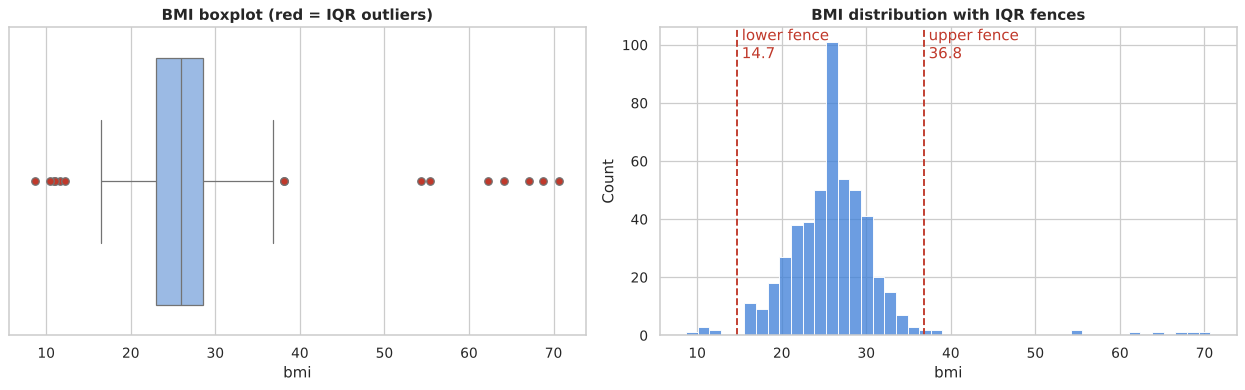

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x=df["bmi"], ax=axes[0], color="#8fb8f0", flierprops=dict(markerfacecolor="#c0392b"))
axes[0].set_title("BMI boxplot (red = IQR outliers)")
sns.histplot(df["bmi"], bins=45, ax=axes[1], color="#3b7dd8")
for v, l in [(lo, "lower fence"), (hi, "upper fence")]:
    axes[1].axvline(v, color="#c0392b", ls="--"); axes[1].text(v, axes[1].get_ylim()[1] * 0.9, f" {l}\n {v:.1f}", color="#c0392b")
axes[1].set_title("BMI distribution with IQR fences")
plt.tight_layout(); plt.savefig(VIZ + "07_iqr_bmi_outliers.png", dpi=150)
plt.show()

In [27]:
df_iqr = df.loc[~iqr_mask].copy()
print(f"Rows before: {len(df)} | removed: {int(iqr_mask.sum())} | rows after: {len(df_iqr)}")
df_iqr.to_csv(PROC + "outliers_removed_iqr.csv", index=False)

Rows before: 500 | removed: 15 | rows after: 485

**Interpretation – IQR**
* Q1 = 23.00, Q3 = 28.52 → IQR = 5.52, fences **14.71 – 36.81**. **15 BMI values** are flagged (6 too low, 9 too high) vs only 7 found by the Z-score rule.
* 13 of the 15 are real corrupted values; two patients with BMI 38.1 are genuine (obese) measurements – a **false positive** of the rule. The IQR method is distribution-free and robust (quartiles are not moved by outliers) but can be strict on skewed columns.

### B.5 Percentile method – cap below the 1st and above the 99th percentile (*Task 3c*)

In [28]:
df_pct = df.copy()
rows = []
for c in OUTCOLS:
    p1, p99 = df[c].quantile([0.01, 0.99])
    n_lo, n_hi = int((df[c] < p1).sum()), int((df[c] > p99).sum())
    df_pct[c] = df[c].clip(p1, p99)
    rows.append({"column": c, "1st pct": p1, "99th pct": p99, "capped low": n_lo, "capped high": n_hi,
                 "min after": df_pct[c].min(), "max after": df_pct[c].max()})
df_pct.to_csv(PROC + "outliers_capped_percentile.csv", index=False)
pd.DataFrame(rows).set_index("column").round(2)

,1st pct,99th pct,capped low,capped high,min after,max after
column,,,,,,
bmi,12.19,55.47,5,5,12.19,55.47
blood_pressure,97.70,237.54,5,5,97.70,237.54
cholesterol,119.55,508.98,5,5,119.55,508.98
glucose,66.99,434.57,5,5,66.99,434.57


### B.6 Winsorization – cap extreme values instead of removing them (*Task 4*)
`scipy.stats.mstats.winsorize(limits=(0.05, 0.05))` replaces the lowest 5 % of values with the 5th-percentile value and the highest 5 % with the 95th-percentile value (symmetric, more aggressive than the 1 %/99 % percentile cap).

In [29]:
WIN = 0.05
df_win = df.copy()
rows = []
for c in OUTCOLS:
    w = np.asarray(mstats.winsorize(df[c].values, limits=(WIN, WIN)))
    rows.append({"column": c, "values changed": int((w != df[c].values).sum()),
                 "min before": df[c].min(), "min after": w.min(), "max before": df[c].max(), "max after": w.max()})
    df_win[c] = w
df_win.to_csv(PROC + "outliers_winsorized.csv", index=False)
pd.DataFrame(rows).set_index("column").round(2)

,values changed,min before,min after,max before,max after
column,,,,,
bmi,50,8.7,18.2,70.7,32.9
blood_pressure,49,94.4,107.1,265.4,141.8
cholesterol,50,50.0,141.6,618.3,248.1
glucose,50,65.0,71.7,499.0,113.3


**Interpretation – percentile cap vs winsorization**
* **Percentile (1 % / 99 %)** only touches 5 values per tail per column. Because about 2.5 % of each column is corrupted, the 99th percentile *is itself an outlier* (glucose cap = 434.6, cholesterol cap = 509.0, blood-pressure cap = 237.5). The values are capped to another extreme value, so the problem stays – 50 corrupted cells are still outside the true range afterwards (see B.9).
* **Winsorization (5 % each side)** pulls glucose max from 499 → 113.3, cholesterol 618 → 248.1, blood pressure 265 → 141.8 and BMI 70.7 → 32.9 (and BMI min 8.7 → 18.2). All extremes are gone and no row is lost, but ≈ 50 values per column (10 %) are modified, including some legitimate ones.

### B.7 Which method flags what? (all four columns, all detection rules)

In [30]:
det = pd.DataFrame({
    "Z-score (|z|>3)":       {c: int(z_flags(df[c]).sum()) for c in OUTCOLS},
    "Modified Z (MAD>3.5)":  {c: int(modz_flags(df[c]).sum()) for c in OUTCOLS},
    "IQR (1.5 x IQR)":       {c: int(iqr_flags(df[c]).sum()) for c in OUTCOLS},
    "Percentile (<1% or >99%)": {c: int(((df[c] < df[c].quantile(.01)) | (df[c] > df[c].quantile(.99))).sum()) for c in OUTCOLS},
    "Winsorize 5% (values changed)": {c: int(((df[c] < df[c].quantile(.05)) | (df[c] > df[c].quantile(.95))).sum()) for c in OUTCOLS},
})
# ground truth: how many cells were *really* corrupted?  (value differs from the true, pre-corruption value)
det["TRUE injected outliers"] = {c: int((raw[c].notna() & (raw[c].round(1) != truth[c].round(1))).sum()) for c in OUTCOLS}
det

,Z-score (|z|>3),Modified Z (MAD>3.5),IQR (1.5 x IQR),Percentile (<1% or >99%),Winsorize 5% (values changed),TRUE injected outliers
bmi,7,12,15,10,50,13
blood_pressure,12,12,22,10,49,12
cholesterol,8,13,14,10,50,13
glucose,12,12,13,10,50,12


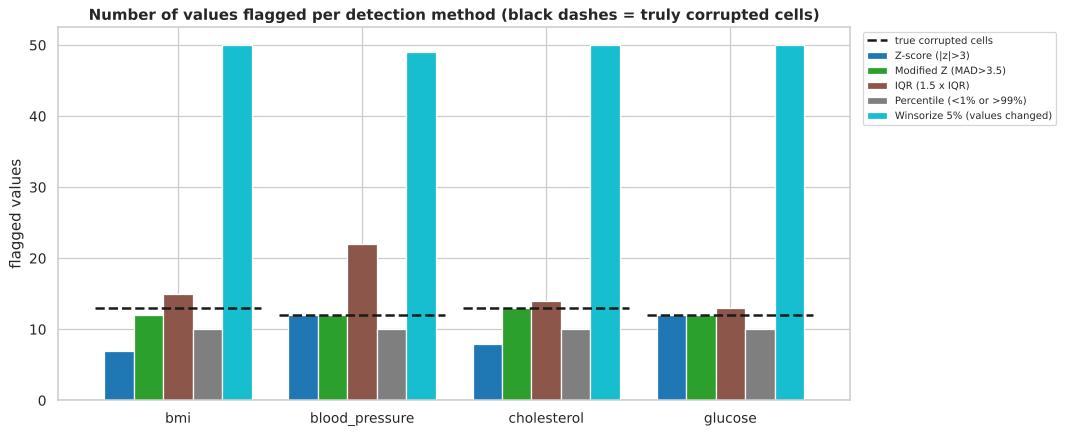

In [31]:
ax = det.drop(columns="TRUE injected outliers").plot(kind="bar", figsize=(12, 5), width=0.8, colormap="tab10")
for i, c in enumerate(OUTCOLS):
    ax.hlines(det.loc[c, "TRUE injected outliers"], i - 0.45, i + 0.45, color="k", ls="--", lw=2,
              label="true corrupted cells" if i == 0 else None)
ax.set_title("Number of values flagged per detection method (black dashes = truly corrupted cells)")
ax.set_ylabel("flagged values"); ax.set_xlabel(""); plt.xticks(rotation=0); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.savefig(VIZ + "08_outlier_detection_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation – detection rules compared with the true number of corrupted cells**
* The robust **modified Z-score (MAD)** is the most accurate detector here (12, 12, 13, 12 flags vs 13, 12, 13, 12 truly corrupted cells).
* **IQR** is close but slightly over-flags (e.g. 22 blood-pressure values vs 12 true) because genuinely high but legitimate patients fall outside the fences.
* **Classic Z-score** under-detects BMI (7 of 13) and cholesterol (8 of 13) because the outliers inflate the standard deviation.
* **Percentile** and **Winsorization** flag a *fixed share* of the data (≈ 2 % and 10 %) regardless of how many outliers really exist – they are treatments, not detectors.

### B.8 Dataset shape & summary – before vs after outlier treatment (*Task 5*)
For a **fair comparison** every treatment is now applied to *all four* columns that contain outliers.

In [32]:
def t_none(d, cols):            return d.copy()
def t_z_remove(d, cols):        return d.loc[~np.any([z_flags(d[c]) for c in cols], axis=0)].copy()
def t_iqr_remove(d, cols):      return d.loc[~np.any([iqr_flags(d[c]) for c in cols], axis=0)].copy()
def t_pct_cap(d, cols):
    o = d.copy()
    for c in cols: o[c] = d[c].clip(*d[c].quantile([0.01, 0.99]))
    return o
def t_winsor(d, cols, lim=WIN):
    o = d.copy()
    for c in cols: o[c] = np.asarray(mstats.winsorize(d[c].values, limits=(lim, lim)))
    return o
def t_iqr_cap(d, cols):
    o = d.copy()
    for c in cols: o[c] = d[c].clip(*iqr_bounds(d[c]))
    return o

TREATMENTS = {
    "No treatment": t_none,
    "Z-score removal (|z|>3)": t_z_remove,
    "IQR removal (1.5xIQR)": t_iqr_remove,
    "Percentile cap (1%-99%)": t_pct_cap,
    "Winsorization (5%)": t_winsor,
    "IQR capping (1.5xIQR)": t_iqr_cap,
}
treated = {n: f(df, OUTCOLS) for n, f in TREATMENTS.items()}

shape_tbl = pd.DataFrame({"rows": {n: d.shape[0] for n, d in treated.items()},
                          "columns": {n: d.shape[1] for n, d in treated.items()}})
shape_tbl["rows lost"] = df.shape[0] - shape_tbl["rows"]
shape_tbl["data loss %"] = (shape_tbl["rows lost"] / df.shape[0] * 100).round(1)
shape_tbl

,rows,columns,rows lost,data loss %
No treatment,500,9,0,0.0
Z-score removal (|z|>3),462,9,38,7.6
IQR removal (1.5xIQR),438,9,62,12.4
Percentile cap (1%-99%),500,9,0,0.0
Winsorization (5%),500,9,0,0.0
IQR capping (1.5xIQR),500,9,0,0.0


In [33]:
summ = pd.concat({n: d[OUTCOLS].agg(["mean", "std", "min", "max"]).T for n, d in treated.items()}, axis=0).round(2)
summ.index.names = ["treatment", "column"]
summ.unstack("treatment")["std"]       # compare the spread (std) of every column under each treatment

treatment,No treatment,Z-score removal (|z|>3),IQR removal (1.5xIQR),Percentile cap (1%-99%),Winsorization (5%),IQR capping (1.5xIQR)
column,,,,,,
bmi,6.23,4.41,3.98,5.52,3.95,4.38
blood_pressure,20.08,10.06,9.28,18.97,9.45,10.56
cholesterol,54.17,33.09,29.54,48.96,29.28,32.67
glucose,51.06,11.42,11.27,48.55,11.20,12.16


In [34]:
summ.unstack("treatment")["max"]

treatment,No treatment,Z-score removal (|z|>3),IQR removal (1.5xIQR),Percentile cap (1%-99%),Winsorization (5%),IQR capping (1.5xIQR)
column,,,,,,
bmi,70.7,38.1,36.8,55.47,32.9,36.81
blood_pressure,265.4,153.1,149.1,237.54,141.8,149.46
cholesterol,618.3,283.5,263.8,508.98,248.1,282.33
glucose,499.0,125.7,120.1,434.57,113.3,121.84


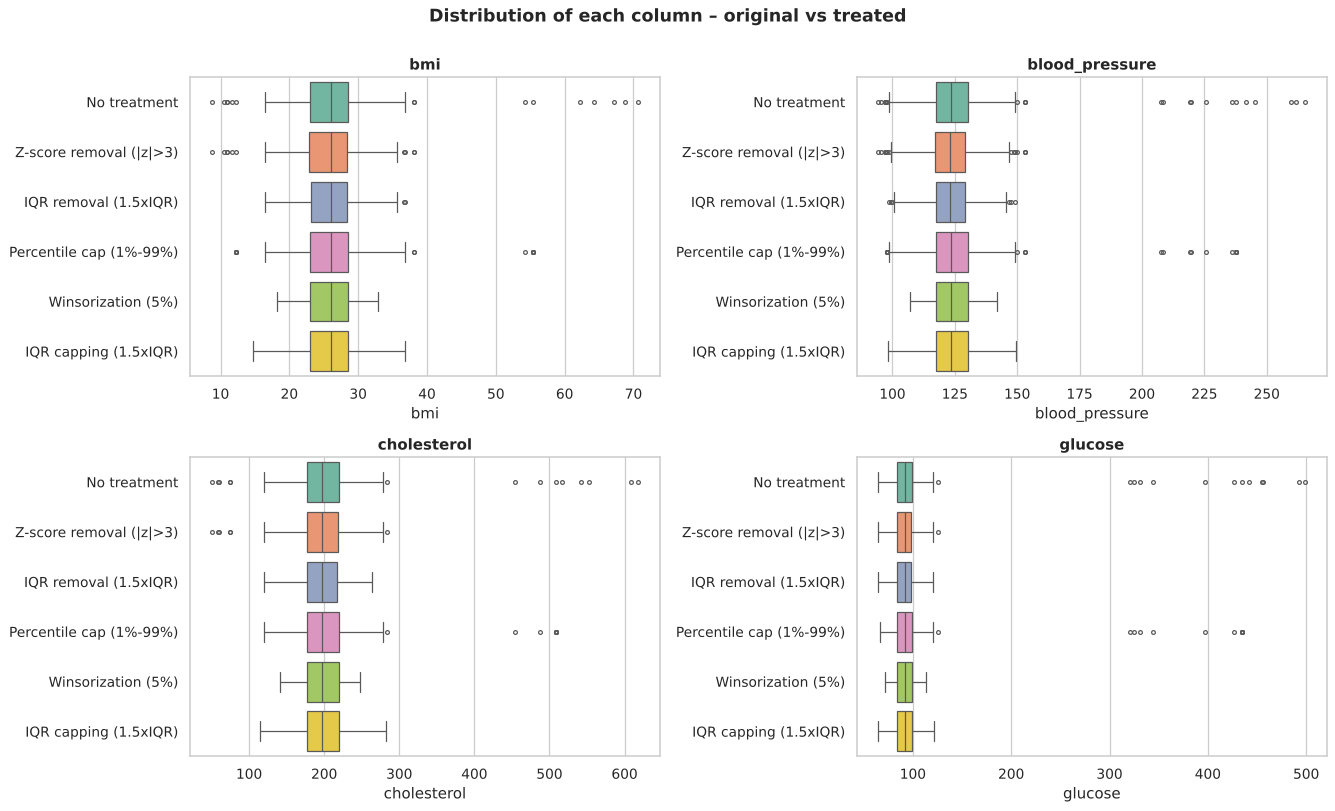

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
long = pd.concat([d[OUTCOLS].assign(treatment=n) for n, d in treated.items()])
for ax, c in zip(axes.ravel(), OUTCOLS):
    sns.boxplot(data=long, y="treatment", x=c, ax=ax, palette="Set2", flierprops=dict(markersize=3))
    ax.set_title(c); ax.set_ylabel("")
plt.suptitle("Distribution of each column – original vs treated", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(); plt.savefig(VIZ + "09_before_after_outlier_treatment.png", dpi=150, bbox_inches="tight")
plt.show()

### B.9 Which treatment preserves data quality best?
We use four yardsticks, three of which are possible only because we know the true values:

1. **Rows retained** (no data loss).  
2. **Error vs truth** – average normalised RMSE between the treated values and the original, uncorrupted values on the rows that remain (lower = closer to reality).  
3. **Cells still outside the true physiological range** – corrupted values that survived the treatment.  
4. **Downstream usefulness** – 5-fold × 5-repeat cross-validated ROC-AUC of a logistic regression predicting `disease_risk`.

In [36]:
def cv_auc(d, repeats=5):
    X = d[["age", "bmi", "blood_pressure", "cholesterol", "glucose"]].astype(float).copy()
    X["male"] = (d["gender"] == "Male").astype(float)
    X = pd.concat([X, pd.get_dummies(d["region"], prefix="region").astype(float)], axis=1)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=SEED)
    s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, d["disease_risk"], cv=cv, scoring="roc_auc")
    return s.mean(), s.std()

tr = truth.set_index("patient_id")
rows = []
for n, d in treated.items():
    t = tr.loc[d["patient_id"]]
    nrmse = np.mean([np.sqrt(((d[c].values - t[c].values) ** 2).mean()) / truth[c].std() for c in OUTCOLS])
    outside = int(sum(((d[c].values < truth[c].min() - 1e-9) | (d[c].values > truth[c].max() + 1e-9)).sum() for c in OUTCOLS))
    auc, auc_sd = cv_auc(d)
    rows.append({"treatment": n, "rows_kept": len(d), "data_loss_%": round((1 - len(d) / len(df)) * 100, 1),
                 "NRMSE_vs_truth": nrmse, "cells_outside_true_range": outside,
                 "avg_|skew|": d[OUTCOLS].skew().abs().mean(), "cv_AUC": auc, "cv_AUC_std": auc_sd})
outlier_eval = pd.DataFrame(rows).set_index("treatment")
outlier_eval.round(4).to_csv(PROC + "outlier_method_comparison.csv")
outlier_eval.round(4)

,rows_kept,data_loss_%,NRMSE_vs_truth,cells_outside_true_range,avg_|skew|,cv_AUC,cv_AUC_std
treatment,,,,,,,
No treatment,500,0.0,2.1282,50,4.2661,0.8332,0.0395
Z-score removal (|z|>3),462,7.6,0.3160,11,0.2878,0.8839,0.0350
IQR removal (1.5xIQR),438,12.4,0.2208,0,0.0765,0.8727,0.0270
Percentile cap (1%-99%),500,0.0,1.9401,50,3.7811,0.8392,0.0393
Winsorization (5%),500,0.0,0.4044,0,0.1053,0.8750,0.0365
IQR capping (1.5xIQR),500,0.0,0.4771,11,0.1025,0.8700,0.0374


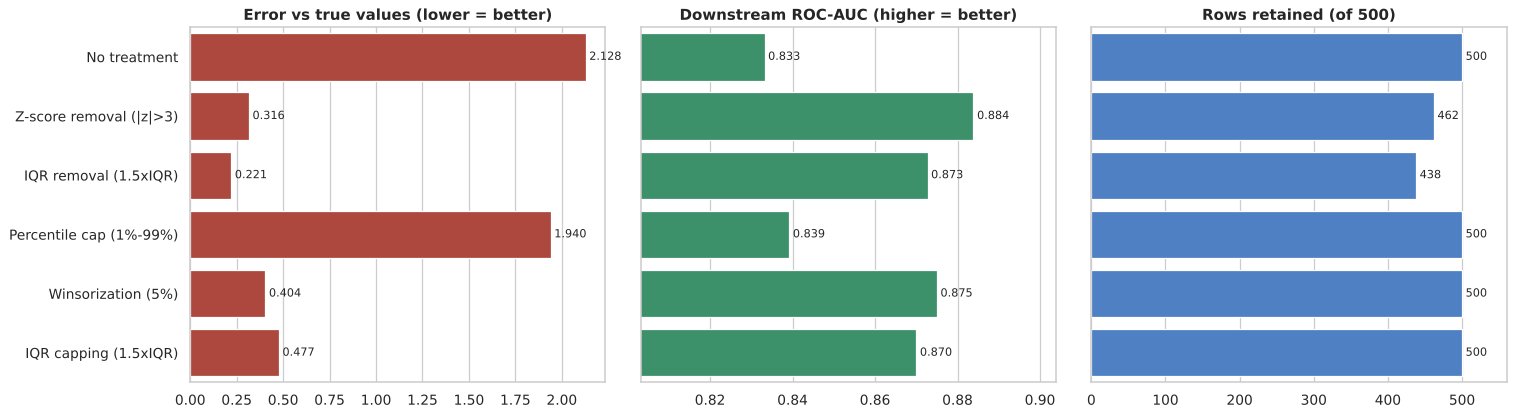

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
order = outlier_eval.index
for ax, (col, ttl, clr, fmt) in zip(axes, [("NRMSE_vs_truth", "Error vs true values (lower = better)", "#c0392b", "{:.3f}"),
                                           ("cv_AUC", "Downstream ROC-AUC (higher = better)", "#2e9e6b", "{:.3f}"),
                                           ("rows_kept", "Rows retained (of 500)", "#3b7dd8", "{:.0f}")]):
    sns.barplot(x=outlier_eval[col], y=order, color=clr, ax=ax)
    for i, v in enumerate(outlier_eval[col]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9)
    ax.set_title(ttl); ax.set_ylabel(""); ax.set_xlabel("")
    if col == "cv_AUC": ax.set_xlim(outlier_eval[col].min() - 0.03, outlier_eval[col].max() + 0.02)
    if col == "rows_kept": ax.set_xlim(0, 560)
    if col != "NRMSE_vs_truth": ax.set_yticklabels([])
plt.tight_layout(); plt.savefig(VIZ + "10_outlier_method_evaluation.png", dpi=150)
plt.show()

**Interpretation – which treatment preserves data quality best?**
* **No treatment**: error vs truth 2.13, 50 cells beyond the true range, ROC-AUC 0.833.
* **Percentile cap 1 %/99 %**: practically useless here (error 1.94, still 50 extreme cells) because the cap value is itself an outlier.
* **Removal (Z-score / IQR)** gives the cleanest values (error 0.316 / 0.221) but **loses 7.6 % / 12.4 % of the patients**; IQR removal also removes legitimate extreme patients.
* **Winsorization 5 %** keeps all 500 rows, leaves **0** values outside the true range, error 0.404 and AUC 0.875.
* **IQR capping** keeps all rows too (error 0.477, 11 cells still slightly out of range, AUC 0.870).
* The AUC differences between the treatments (0.870 – 0.884) are smaller than the CV standard deviation (≈ 0.03), so they are statistically equivalent – the real gain is versus *no treatment* (0.833 → ≈ 0.875). Note that the removal methods are scored on fewer rows, so their AUC is not strictly comparable.

**Verdict:** *Winsorization (capping) preserves data quality best* – no data loss, no extreme values left, good downstream performance. Removal is only justified when an outlier is a certain measurement error and the data set is large.

## Part C – Final Clean Dataset
**Tasks covered:** (6) final cleaned dataset with all missing values and outliers handled, (7) brief report, plus **feature engineering** to make the data machine-learning ready.

### C.1 Does the order of operations matter?
So far we followed the task order (*impute → treat outliers*). But extreme values also distort mean / KNN / MICE imputations, so we test three pipelines against the ground truth:

| Pipeline | Steps |
|---|---|
| **A. Impute → Treat** | best imputation of Part A, then cap outliers |
| **B. Flag → Impute** | turn IQR-flagged outliers into *missing*, then impute everything (outliers are re-estimated from the other columns) |
| **C. Cap → Impute** | cap outliers on the observed values first, then impute |

In [38]:
raw = pd.read_csv(RAW)
truth = pd.read_csv(TRUTH)
tr = truth.set_index("patient_id")

def impute_by_name(name, d):
    """Re-run an imputation technique from Part A on any dataframe."""
    if name.startswith("KNN"):
        return multivariate_impute(d, "knn")
    if name.startswith("MICE"):
        return multivariate_impute(d, "mice")
    o = d.copy()
    strat = "median" if name.startswith("Median") else "mean"
    o[NUM + ["blood_pressure"]] = SimpleImputer(strategy=strat).fit_transform(d[NUM + ["blood_pressure"]]); o["age"] = o["age"].round()
    o[CAT] = SimpleImputer(strategy="most_frequent").fit_transform(d[CAT])
    return o

def full_nrmse(d):
    """error vs truth over ALL cells of the 4 numeric outlier columns + age"""
    return float(np.mean([np.sqrt(((d[c].values - tr.loc[d["patient_id"], c].values) ** 2).mean()) / truth[c].std() for c in NUM + ["blood_pressure"]]))

cap_name = outlier_eval.loc[[n for n in outlier_eval.index if "cap" in n.lower() or "winsor" in n.lower()], "NRMSE_vs_truth"].idxmin()
print("Best capping rule from Part B (lowest error vs truth, keeps all rows):", cap_name)
CAPFUN = TREATMENTS[cap_name]

# ---- pipeline B preparation: IQR-flagged outliers become NaN, then every technique is re-scored ----
flagged = raw.copy()
for c in OUTCOLS:
    flagged.loc[iqr_flags(raw[c].dropna()).reindex(raw.index, fill_value=False), c] = np.nan
NUMB = NUM + ["blood_pressure"]
flag_mask = flagged[NUMB].isna()
print("Cells to re-estimate in pipeline B (missing + flagged outliers):")
print(flag_mask.sum().to_dict(), "| total =", int(flag_mask.sum().sum()))

def score_flagged(d, name):
    row = {"method": name}
    for c in NUMB:
        err = d.loc[flag_mask[c], c].astype(float).values - tr.loc[d.loc[flag_mask[c], "patient_id"], c].values
        row[c + "_NRMSE"] = np.sqrt((err ** 2).mean()) / truth[c].std()
    row["avg_NRMSE"] = np.mean([row[c + "_NRMSE"] for c in NUMB])
    for c in CAT:
        m = missing_mask[c]
        row[c + "_acc"] = (d.loc[m, c] == truth.loc[m, c]).mean()
    row["avg_cat_accuracy"] = np.mean([row[c + "_acc"] for c in CAT])
    return row

cands = {n: impute_by_name(n, flagged) for n in ["Mean + Most-frequent", "Median + Most-frequent", "KNN (k=5)", "MICE (Bayesian Ridge)"]}
imp_after_flag = pd.DataFrame([score_flagged(d, n) for n, d in cands.items()]).set_index("method")
imp_after_flag.round(4).to_csv(PROC + "imputation_comparison_after_outlier_flagging.csv")
best_num2 = imp_after_flag["avg_NRMSE"].idxmin()
print("\nBest technique once outliers are neutralised:", best_num2)
imp_after_flag.round(3)

Best capping rule from Part B (lowest error vs truth, keeps all rows): Winsorization (5%)
Cells to re-estimate in pipeline B (missing + flagged outliers):
{'age': 30, 'bmi': 53, 'cholesterol': 48, 'glucose': 48, 'blood_pressure': 22} | total = 201

Best technique once outliers are neutralised: MICE (Bayesian Ridge)

,age_NRMSE,bmi_NRMSE,cholesterol_NRMSE,glucose_NRMSE,blood_pressure_NRMSE,avg_NRMSE,gender_acc,region_acc,avg_cat_accuracy
method,,,,,,,,,
Mean + Most-frequent,0.934,0.828,1.298,1.099,1.973,1.226,0.60,0.32,0.46
Median + Most-frequent,0.934,0.830,1.299,1.102,1.968,1.227,0.60,0.32,0.46
KNN (k=5),0.913,0.866,1.282,0.992,1.577,1.126,0.56,0.16,0.36
MICE (Bayesian Ridge),0.734,0.790,1.132,0.738,1.499,0.979,0.68,0.32,0.50


**Interpretation – imputation once outliers are neutralised**
* 201 numeric cells now have to be re-estimated (140 originally missing numeric cells + 61 IQR-flagged outliers: age 30, BMI 53, cholesterol 48, glucose 48, blood pressure 22).
* **MICE is now the best technique (avg NRMSE 0.979)**, followed by KNN (1.126) and mean / median (≈ 1.226). Age (0.73) and glucose (0.74) improve the most because MICE can use the real relationships (age ↔ blood pressure / cholesterol, BMI ↔ glucose).
* In Part A the median looked best only because it was the technique least harmed by outliers. With clean neighbours and regressors, the multivariate methods win. Scores remain around 1 for blood pressure / cholesterol because the re-estimated cells include genuine extreme patients that no imputer can predict well.

In [39]:
# A. impute -> cap
pipe_A = CAPFUN(pd.read_csv(PROC + "imputed_best.csv"), OUTCOLS)

# B. flag outliers as NaN -> impute with the technique that won above
pipe_B = impute_by_name(best_num2, flagged)

# C. cap observed values first -> impute
capped_first = raw.copy()
for c in OUTCOLS:
    obs = raw[c].dropna()
    if "IQR" in cap_name:
        lo_c, hi_c = iqr_bounds(obs)
    else:
        lo_c, hi_c = obs.quantile([0.05, 0.95] if "Winsor" in cap_name else [0.01, 0.99])
    capped_first[c] = raw[c].clip(lo_c, hi_c)
pipe_C = impute_by_name(best_num, capped_first)

baseline = impute_by_name("Mean + Most-frequent", raw)        # naive pipeline: mean impute, ignore outliers        # naive pipeline: mean impute, ignore outliers
pipelines = {"Baseline (mean impute, no outlier handling)": baseline,
             "A. Impute -> Cap": pipe_A, "B. Flag outliers -> Impute": pipe_B, "C. Cap -> Impute": pipe_C}
rows = []
for n, d in pipelines.items():
    auc, sd = cv_auc(d)
    rows.append({"pipeline": n, "NRMSE_vs_truth_all_cells": full_nrmse(d),
                 "cells_outside_true_range": int(sum(((d[c] < truth[c].min() - 1e-9) | (d[c] > truth[c].max() + 1e-9)).sum() for c in OUTCOLS)),
                 "missing_cells": int(d.isna().sum().sum()), "cv_AUC": auc, "cv_AUC_std": sd})
pipe_eval = pd.DataFrame(rows).set_index("pipeline")
pipe_eval.round(4).to_csv(PROC + "pipeline_order_comparison.csv")
pipe_eval.round(4)

,NRMSE_vs_truth_all_cells,cells_outside_true_range,missing_cells,cv_AUC,cv_AUC_std
pipeline,,,,,
"Baseline (mean impute, no outlier handling)",1.7503,50,0,0.8327,0.0396
A. Impute -> Cap,0.3693,0,0,0.8750,0.0365
B. Flag outliers -> Impute,0.2662,0,0,0.8754,0.0390
C. Cap -> Impute,0.3708,0,0,0.8751,0.0365


**Interpretation – order of operations**

| Pipeline | Error vs truth (all cells) | Cells outside true range | CV ROC-AUC |
|---|---|---|---|
| Baseline (mean impute, no outlier handling) | 1.750 | 50 | 0.833 |
| A. Impute → Winsorize | 0.369 | 0 | 0.875 |
| **B. Flag outliers → MICE impute** | **0.266** | 0 | 0.875 |
| C. Winsorize → Impute | 0.371 | 0 | 0.875 |

All three pipelines clearly beat the baseline. **Pipeline B is the most accurate (error 0.266, ~28 % lower than A / C)** because the extreme values are treated as *missing* and re-estimated from the patient's other measurements, instead of being clamped to an arbitrary cap. It is therefore used for the final dataset. (Pipeline A is the order suggested by the task text and is also valid.)

### C.2 Build and save the final cleaned dataset – *Task 6*

In [40]:
best_pipe = pipe_eval.drop(index="Baseline (mean impute, no outlier handling)")["NRMSE_vs_truth_all_cells"].idxmin()
print("Selected final pipeline:", best_pipe)
final = pipelines[best_pipe].copy()

# tidy types / precision
final["age"] = final["age"].round().astype(int)
for c in ["bmi", "blood_pressure", "cholesterol", "glucose"]:
    final[c] = final[c].round(1)
final = final[["patient_id", "age", "gender", "region", "bmi", "blood_pressure", "cholesterol", "glucose", "disease_risk"]]

# ---- final integrity checks ----
assert final.isna().sum().sum() == 0, "missing values remain!"
assert final["patient_id"].is_unique
assert set(final["gender"]) <= {"Male", "Female"} and set(final["region"]) <= {"North", "South", "East", "West"}
print("✔ no missing values   ✔ unique patient ids   ✔ valid categories   ✔ shape:", final.shape)
final.to_csv(PROC + "cleaned_patient_health_records.csv", index=False)
final.describe().T.round(2)

Selected final pipeline: B. Flag outliers -> Impute
✔ no missing values   ✔ unique patient ids   ✔ valid categories   ✔ shape: (500, 9)

,count,mean,std,min,25%,50%,75%,max
age,500.0,51.96,14.06,18.0,42.00,52.00,60.25,90.0
bmi,500.0,25.77,4.14,16.5,22.90,25.90,28.52,38.1
blood_pressure,500.0,123.46,9.20,98.5,117.40,123.00,129.30,149.1
cholesterol,500.0,196.52,30.09,120.0,176.75,196.30,217.95,283.5
glucose,500.0,91.25,11.44,65.0,83.75,91.55,99.00,120.1
disease_risk,500.0,0.39,0.49,0.0,0.00,0.00,1.00,1.0


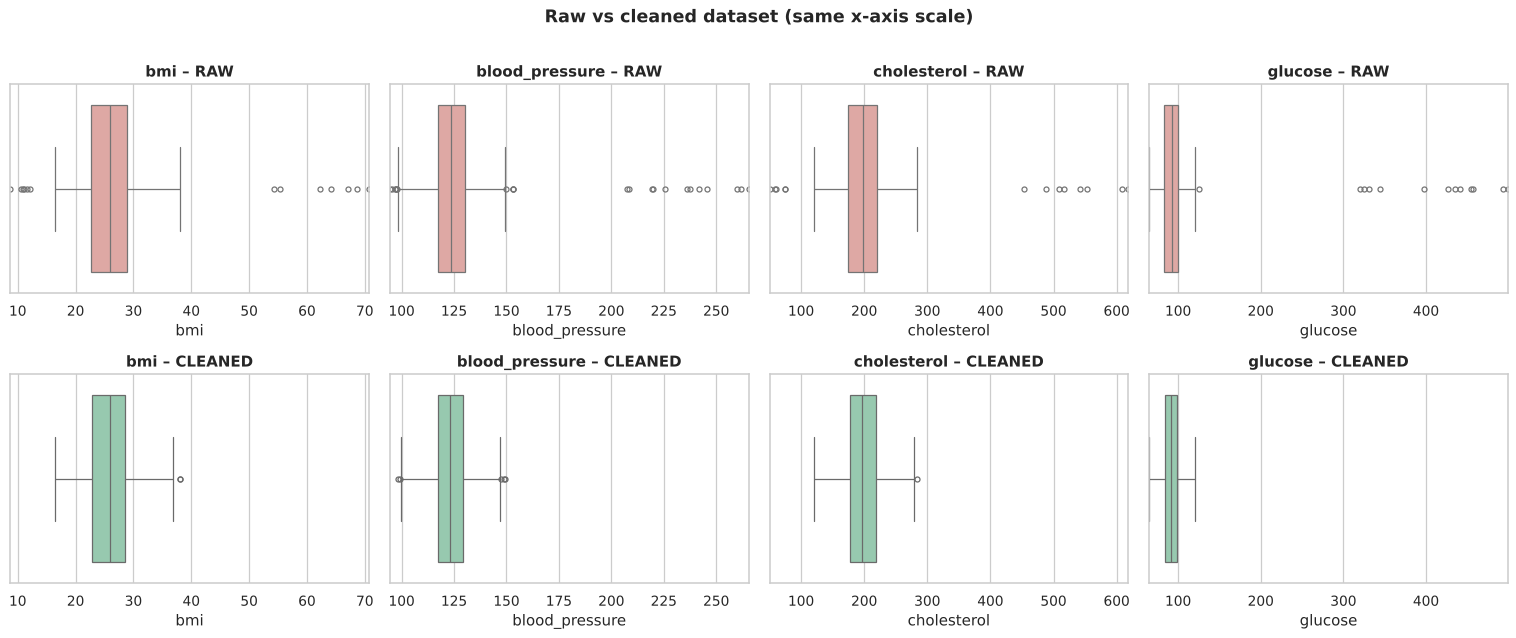

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for j, c in enumerate(OUTCOLS):
    sns.boxplot(x=raw[c], ax=axes[0, j], color="#e8a09a", flierprops=dict(markersize=4)); axes[0, j].set_title(f"{c} – RAW")
    sns.boxplot(x=final[c], ax=axes[1, j], color="#8fd1ae", flierprops=dict(markersize=4)); axes[1, j].set_title(f"{c} – CLEANED")
    lim = (min(raw[c].min(), final[c].min()), max(raw[c].max(), final[c].max()))
    axes[0, j].set_xlim(lim); axes[1, j].set_xlim(lim)
plt.suptitle("Raw vs cleaned dataset (same x-axis scale)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.savefig(VIZ + "11_raw_vs_cleaned_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### C.3 Feature engineering – making the data ML-ready
Clinically meaningful categories (WHO / AHA / ADA thresholds), a *metabolic-flag count*, and the encoding + scaling a model needs.

In [42]:
fe = final.copy()
fe["age_group"] = pd.cut(fe["age"], [0, 30, 45, 60, 75, 120], labels=["18-30", "31-45", "46-60", "61-75", "76+"])
fe["bmi_category"] = pd.cut(fe["bmi"], [0, 18.5, 25, 30, 100], right=False, labels=["Underweight", "Normal", "Overweight", "Obese"])
fe["bp_category"] = pd.cut(fe["blood_pressure"], [0, 120, 130, 140, 400], right=False, labels=["Normal", "Elevated", "Stage-1 HTN", "Stage-2 HTN"])
fe["cholesterol_category"] = pd.cut(fe["cholesterol"], [0, 200, 240, 1000], right=False, labels=["Desirable", "Borderline", "High"])
fe["glucose_category"] = pd.cut(fe["glucose"], [0, 100, 126, 1000], right=False, labels=["Normal", "Prediabetic", "Diabetic-range"])
fe["metabolic_flags"] = ((fe["bmi"] >= 25).astype(int) + (fe["blood_pressure"] >= 130).astype(int)
                         + (fe["cholesterol"] >= 200).astype(int) + (fe["glucose"] >= 100).astype(int))
fe.to_csv(PROC + "cleaned_with_engineered_features.csv", index=False)
fe.head(8)

,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk,age_group,bmi_category,bp_category,cholesterol_category,glucose_category,metabolic_flags
0,PT0001,57,Male,East,29.1,125.4,184.5,109.6,0,46-60,Overweight,Elevated,Desirable,Prediabetic,2
1,PT0002,36,Male,West,26.3,121.3,190.2,80.5,0,31-45,Overweight,Elevated,Desirable,Normal,1
2,PT0003,63,Female,South,28.3,124.9,205.9,92.1,1,61-75,Overweight,Elevated,Borderline,Normal,2
3,PT0004,66,Male,East,30.3,127.3,217.2,107.4,1,61-75,Obese,Elevated,Borderline,Prediabetic,3
4,PT0005,23,Male,North,21.9,110.8,159.6,90.3,0,18-30,Normal,Normal,Desirable,Normal,0
5,PT0006,32,Female,West,29.4,120.2,184.4,98.0,0,31-45,Overweight,Elevated,Desirable,Normal,1
6,PT0007,54,Female,South,20.8,111.3,206.0,110.7,0,46-60,Normal,Normal,Borderline,Prediabetic,2
7,PT0008,47,Female,East,24.5,115.1,229.7,86.4,0,46-60,Normal,Normal,Borderline,Normal,1


In [43]:
# ---- encoding + scaling -> ml_ready_features.csv ----
ml = pd.DataFrame({"patient_id": fe["patient_id"]})
scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(fe[["age", "bmi", "blood_pressure", "cholesterol", "glucose"]]),
                      columns=[f"{c}_scaled" for c in ["age", "bmi", "blood_pressure", "cholesterol", "glucose"]])
ml = pd.concat([ml, scaled], axis=1)
ml["gender_male"] = (fe["gender"] == "Male").astype(int)
ml = pd.concat([ml, pd.get_dummies(fe["region"], prefix="region").astype(int)], axis=1)
for c in ["age_group", "bmi_category", "bp_category", "cholesterol_category", "glucose_category"]:
    ml[c + "_ord"] = fe[c].cat.codes                                   # ordered categories -> 0,1,2..
ml["metabolic_flags"] = fe["metabolic_flags"]
ml["disease_risk"] = fe["disease_risk"]
ml.to_csv(PROC + "ml_ready_features.csv", index=False)
print("ML-ready matrix:", ml.shape, "| NaNs:", int(ml.isna().sum().sum()))
ml.head(5).round(3)

ML-ready matrix: (500, 18) | NaNs: 0

,patient_id,age_scaled,bmi_scaled,blood_pressure_scaled,cholesterol_scaled,glucose_scaled,gender_male,region_East,region_North,region_South,region_West,age_group_ord,bmi_category_ord,bp_category_ord,cholesterol_category_ord,glucose_category_ord,metabolic_flags,disease_risk
0,PT0001,0.359,0.807,0.211,-0.400,1.606,1,1,0,0,0,2,2,1,0,1,2,0
1,PT0002,-1.137,0.129,-0.234,-0.210,-0.941,1,0,0,0,1,1,2,1,0,0,1,0
2,PT0003,0.786,0.613,0.157,0.312,0.075,0,0,0,1,0,3,2,1,1,0,2,1
3,PT0004,1.000,1.097,0.418,0.688,1.414,1,1,0,0,0,3,3,1,1,1,3,1
4,PT0005,-2.062,-0.936,-1.376,-1.228,-0.083,1,0,1,0,0,0,1,0,0,0,0,0


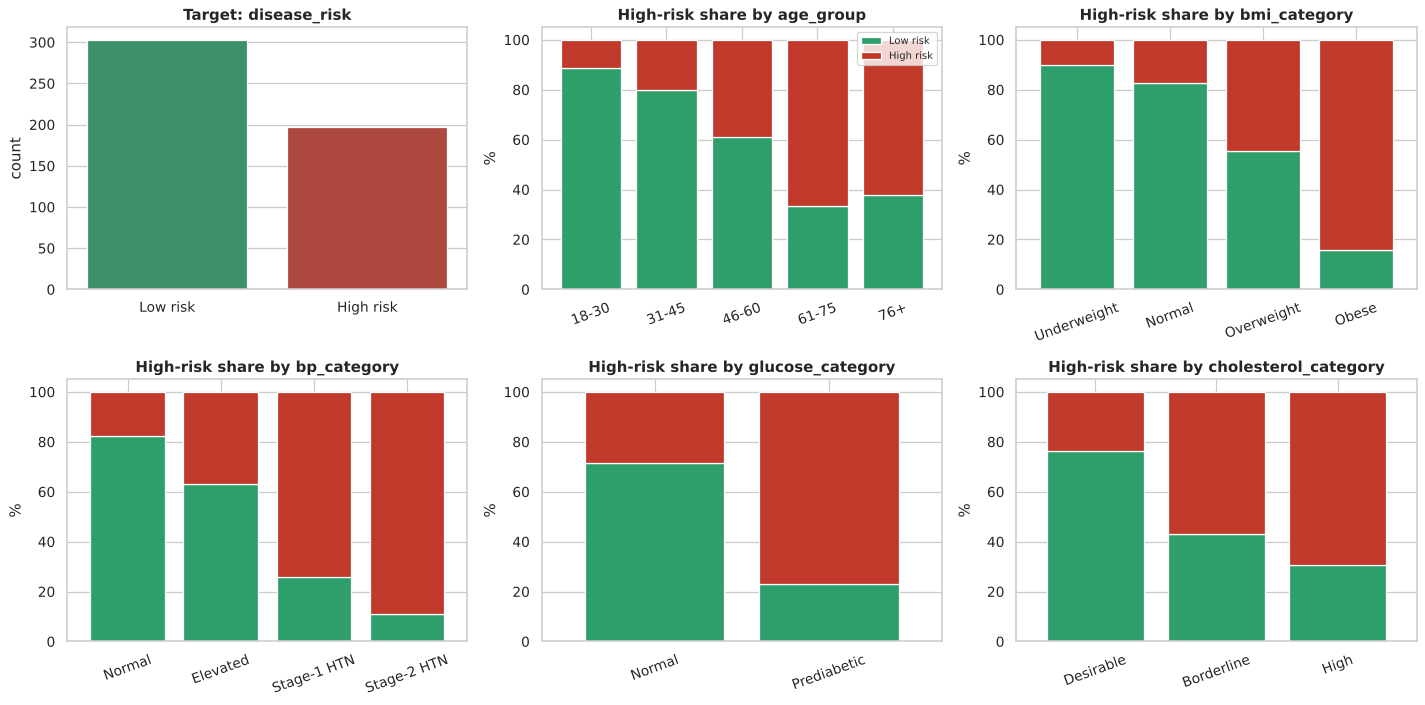

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.countplot(x=fe["disease_risk"].map({0: "Low risk", 1: "High risk"}), ax=axes[0, 0], palette=["#2e9e6b", "#c0392b"])
axes[0, 0].set_title("Target: disease_risk"); axes[0, 0].set_xlabel("")
for ax, c in zip(axes.ravel()[1:], ["age_group", "bmi_category", "bp_category", "glucose_category", "cholesterol_category"]):
    ct = pd.crosstab(fe[c], fe["disease_risk"], normalize="index").mul(100)
    ct.plot(kind="bar", stacked=True, ax=ax, color=["#2e9e6b", "#c0392b"], legend=False, width=0.8)
    ax.set_title(f"High-risk share by {c}"); ax.set_xlabel(""); ax.set_ylabel("%"); ax.tick_params(axis="x", rotation=20)
axes[0, 1].legend(["Low risk", "High risk"], fontsize=8)
plt.tight_layout(); plt.savefig(VIZ + "12_engineered_features_vs_target.png", dpi=150)
plt.show()

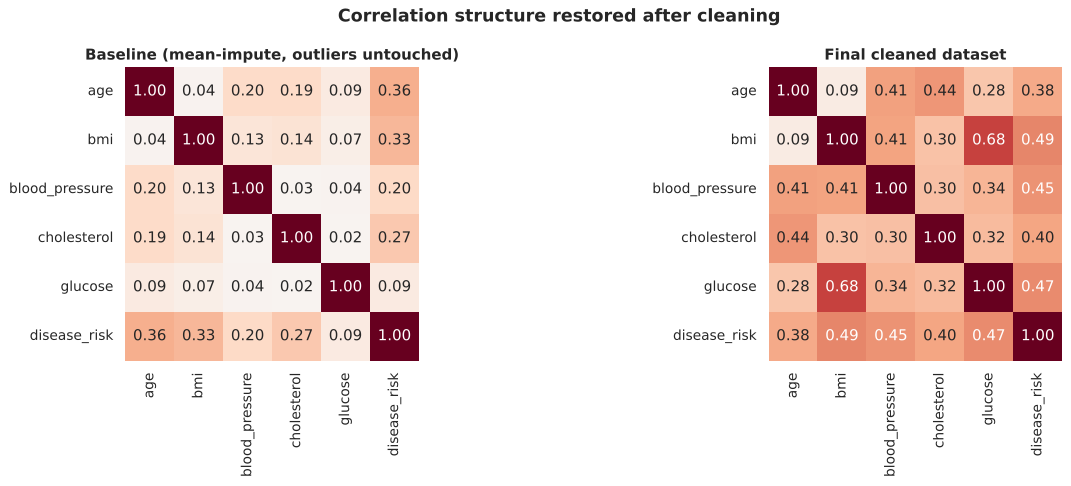

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cols = ["age", "bmi", "blood_pressure", "cholesterol", "glucose", "disease_risk"]
for ax, d, t in zip(axes, [baseline, final], ["Baseline (mean-impute, outliers untouched)", "Final cleaned dataset"]):
    sns.heatmap(d[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False, square=True)
    ax.set_title(t)
plt.suptitle("Correlation structure restored after cleaning", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig(VIZ + "13_correlation_heatmap_before_after.png", dpi=150)
plt.show()

**Interpretation – correlations**
In the baseline data the outliers destroy the relationships between variables (e.g. correlation of glucose with disease risk only 0.09, blood pressure 0.20). After cleaning they return to realistic levels: glucose 0.47, blood pressure 0.45, BMI 0.49, cholesterol 0.40, age 0.38. Age also correlates with blood pressure (0.41) and cholesterol (0.44), the relationships MICE exploited. This is exactly why the cleaned data train better models.

### C.4 Before vs after – dataset quality scorecard & downstream model

In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

def model_scores(d):
    X = d[["age", "bmi", "blood_pressure", "cholesterol", "glucose"]].astype(float).copy()
    X["male"] = (d["gender"] == "Male").astype(float)
    X = pd.concat([X, pd.get_dummies(d["region"], prefix="region").astype(float)], axis=1)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
    out = {}
    for name, mdl in {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                      "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)}.items():
        r = cross_validate(mdl, X, d["disease_risk"], cv=cv, scoring=["roc_auc", "accuracy"])
        out[name] = {"AUC": r["test_roc_auc"].mean(), "Accuracy": r["test_accuracy"].mean()}
    return out

sb, sf = model_scores(baseline), model_scores(final)
model_tbl = pd.DataFrame({(m, k): {"Baseline": sb[m][k], "Cleaned": sf[m][k]} for m in sb for k in ["AUC", "Accuracy"]}).T
model_tbl["Improvement"] = model_tbl["Cleaned"] - model_tbl["Baseline"]
model_tbl.round(4)

Baseline  Cleaned  Improvement
Logistic Regression AUC         0.8306   0.8742       0.0435
                    Accuracy    0.7407   0.7927       0.0520
Random Forest       AUC         0.8540   0.8623       0.0083
                    Accuracy    0.7680   0.7847       0.0167

In [47]:
def scorecard(d, label):
    return {"rows": d.shape[0], "missing cells": int(d.isna().sum().sum()),
            "cells outside true range": int(sum(((d[c] < truth[c].min() - 1e-9) | (d[c] > truth[c].max() + 1e-9)).sum() for c in OUTCOLS)),
            "avg |skewness| (4 cols)": round(d[OUTCOLS].skew().abs().mean(), 2),
            "max glucose": round(d["glucose"].max(), 1), "max cholesterol": round(d["cholesterol"].max(), 1),
            "max blood pressure": round(d["blood_pressure"].max(), 1), "BMI range": f"{d['bmi'].min():.1f} - {d['bmi'].max():.1f}",
            "NRMSE vs truth": round(full_nrmse(d), 3) if d["patient_id"].notna().all() and d.isna().sum().sum() == 0 else "n/a (has NaN)"}
score = pd.DataFrame({"RAW (as received)": scorecard(raw.fillna(raw.median(numeric_only=True)).fillna("?"), "raw"),
                      "BASELINE (mean impute)": scorecard(baseline, "baseline"),
                      "FINAL (cleaned)": scorecard(final, "final")})
score.loc["missing cells", "RAW (as received)"] = int(raw.isna().sum().sum())
score

,RAW (as received),BASELINE (mean impute),FINAL (cleaned)
rows,500,500,500
missing cells,190,0,0
cells outside true range,50,50,0
avg |skewness| (4 cols),4.27,4.26,0.04
max glucose,499.0,499.0,120.1
max cholesterol,618.3,618.3,283.5
max blood pressure,265.4,265.4,149.1
BMI range,8.7 - 70.7,8.7 - 70.7,16.5 - 38.1
NRMSE vs truth,1.748,1.75,0.266


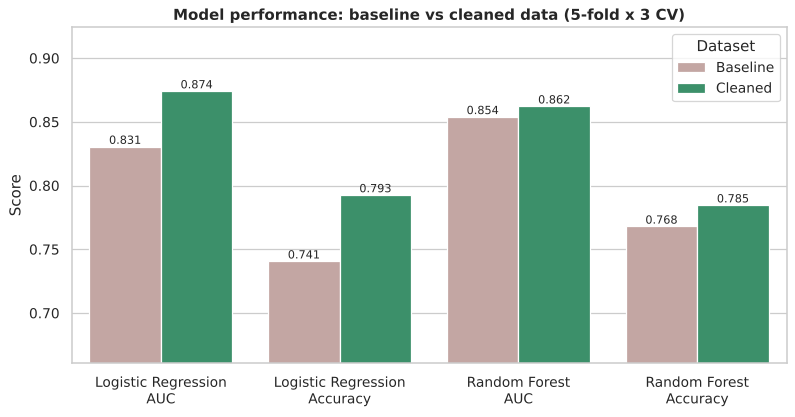

In [48]:
fig, ax = plt.subplots(figsize=(9, 4.8))
plot = model_tbl.reset_index().rename(columns={"level_0": "Model", "level_1": "Metric"})
plot = plot.melt(id_vars=["Model", "Metric", "Improvement"], value_vars=["Baseline", "Cleaned"], var_name="Dataset", value_name="Score")
plot["lbl"] = plot["Model"] + "\n" + plot["Metric"]
sns.barplot(data=plot, x="lbl", y="Score", hue="Dataset", palette=["#c9a29d", "#2e9e6b"], ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
ax.set_ylim(plot["Score"].min() - 0.08, min(1, plot["Score"].max() + 0.05)); ax.set_xlabel(""); ax.set_title("Model performance: baseline vs cleaned data (5-fold x 3 CV)")
plt.tight_layout(); plt.savefig(VIZ + "14_model_performance_baseline_vs_cleaned.png", dpi=150)
plt.show()

**Interpretation – before vs after**
* The cleaned dataset has **0 missing cells** (190 before), **0 values outside the plausible range** (50 before), average |skewness| **0.04** (4.27 before), glucose max 120 (499), cholesterol max 284 (618), systolic BP max 149 (265) and BMI 16.5 – 38.1 (8.7 – 70.7). Error vs the true values fell from 1.75 to 0.27.
* **Logistic Regression** (sensitive to outliers) improved the most: ROC-AUC 0.831 → 0.874 and accuracy 74.1 % → 79.3 %.
* **Random Forest** (robust to outliers) improved less: AUC 0.854 → 0.862, accuracy 76.8 % → 78.5 % – but it still benefits, and its feature importances are no longer driven by garbage values.

### C.5 Save a machine-readable summary (used to build the HTML profiling report and the PDF reports)

In [49]:
import json
summary = {
    "raw_shape": list(raw.shape), "final_shape": list(final.shape), "ml_shape": list(ml.shape),
    "missing_summary": miss.reset_index().rename(columns={"index": "column"}).to_dict("records"),
    "total_missing_cells": int(raw.isna().sum().sum()), "rows_with_missing": int(raw.isna().any(axis=1).sum()),
    "imputation_results": results.round(4).reset_index().to_dict("records"),
    "best_num": best_num, "best_cat": best_cat, "best_num2": best_num2,
    "imp_after_flag": imp_after_flag.round(4).reset_index().to_dict("records"),
    "detection_counts": det.reset_index().rename(columns={"index": "column"}).to_dict("records"),
    "shape_table": shape_tbl.reset_index().rename(columns={"index": "treatment"}).to_dict("records"),
    "outlier_eval": outlier_eval.round(4).reset_index().to_dict("records"),
    "cap_name": cap_name, "pipeline_eval": pipe_eval.round(4).reset_index().to_dict("records"),
    "best_pipeline": best_pipe, "model_table": model_tbl.round(4).reset_index().rename(columns={"level_0": "model", "level_1": "metric"}).to_dict("records"),
    "scorecard": score.astype(str).to_dict(),
}
with open(PROC + "results_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print("Saved results_summary.json")
print("\nFinal files in Data/Processed:")
import os
for f in sorted(os.listdir(PROC)): print("  -", f)

Saved results_summary.json

Final files in Data/Processed:
  - cleaned_patient_health_records.csv
  - cleaned_with_engineered_features.csv
  - imputation_comparison.csv
  - imputation_comparison_after_outlier_flagging.csv
  - imputed_best.csv
  - imputed_knn.csv
  - imputed_mean_mode.csv
  - imputed_median_mode.csv
  - imputed_mice.csv
  - imputed_random_sample_with_indicators.csv
  - missing_value_summary.csv
  - ml_ready_features.csv
  - outlier_method_comparison.csv
  - outliers_capped_percentile.csv
  - outliers_removed_iqr.csv
  - outliers_removed_zscore.csv
  - outliers_winsorized.csv
  - pipeline_order_comparison.csv
  - results_summary.json

---
## C.6 Brief report (Task 7)

**1. Which imputation strategy was most effective?**  
It depends on the state of the data. On the raw data (outliers still present) the *median* was the most robust (avg NRMSE 1.026), while *KNN* and *random sampling* were hurt by the extreme values. After the outliers were neutralised, **MICE** was clearly the best (avg NRMSE 0.979 vs 1.226 for mean / median and 1.126 for KNN). For `gender` and `region` no technique beat the most-frequent category reliably, so the mode (or MICE-decoded label) is sufficient.

**2. Which outlier-handling method preserved data quality best?**  
**Winsorization (5 %)** among the capping methods – no rows lost, no value left outside the plausible range, ROC-AUC 0.875 (vs 0.833 untreated). Z-score and IQR *removal* gave slightly cleaner values but discarded 7.6 % and 12.4 % of the patients. The 1 %/99 % percentile cap was ineffective because ~2.5 % of each column was corrupted. Even better, treating flagged outliers as *missing* and imputing them with MICE (**final pipeline**) gave the lowest error vs the true values (0.266).

**3. How did cleaning improve usability?**  
Missing cells 190 → 0; implausible values 50 → 0; skewness 4.27 → 0.04; correlation with the target restored; Logistic Regression ROC-AUC 0.831 → 0.874 (+4.3 points), accuracy 74.1 % → 79.3 %; Random Forest AUC 0.854 → 0.862. Feature engineering added clinically meaningful categories (WHO BMI, AHA blood pressure, ADA glucose, cholesterol bands, age groups, metabolic-flag count) and an encoded, scaled `ml_ready_features.csv` (500 × 18).

**Limitations / next steps:** the dataset is synthetic (so imputation could be scored exactly), results are averages over cross-validation folds on 500 patients, and the thresholds (|z| > 3, 1.5 × IQR, 5 % winsor limit) are tunable hyper-parameters that should be reviewed with a clinician on real data.